In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


%matplotlib inline
sns.set_theme(style="whitegrid")

# Load the saved dataset
df_cleaned = pd.read_csv("cleaned_aviation_data.csv", low_memory=False)

df_cleaned.shape

(17879, 35)

In [4]:
# Separate fleets 
df_cleaned['Aircraft.Size'] = np.where(df_cleaned['Estimated.Total.People'] >= 20, 'Large Passenger', 'Small Aircraft')

print(" Value Counts After Applying Passenger Threshold of 20 ")
df_cleaned['Aircraft.Size'].value_counts()

 Value Counts After Applying Passenger Threshold of 20 


Aircraft.Size
Small Aircraft     17001
Large Passenger      878
Name: count, dtype: int64

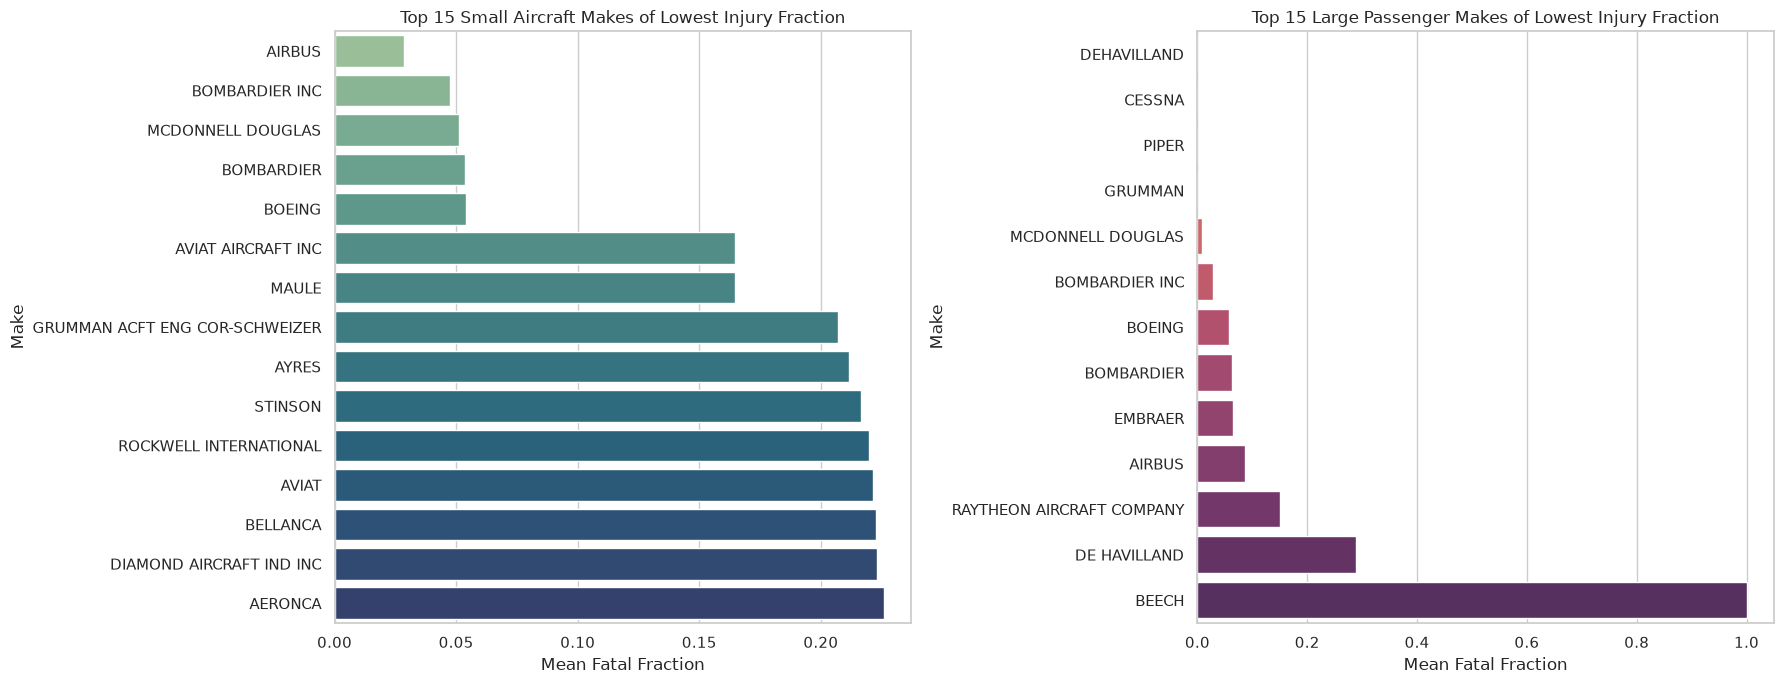

In [5]:
# Group by size and make
make_safety = df_cleaned.groupby(['Aircraft.Size', 'Make'])['Severe.Injury.Rate'].mean().reset_index()

# Extract top 15 lowest rates for both groups
top15_small_makes = make_safety[make_safety['Aircraft.Size'] == 'Small Aircraft'].sort_values('Severe.Injury.Rate').head(15)
top15_large_makes = make_safety[make_safety['Aircraft.Size'] == 'Large Passenger'].sort_values('Severe.Injury.Rate').head(15)

# Plotting the side-by-side comparisons
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.barplot(data=top15_small_makes, x='Severe.Injury.Rate', y='Make', hue='Make', ax=axes[0], palette='crest', legend=False)
axes[0].set_title('Top 15 Small Aircraft Makes of Lowest Injury Fraction')
axes[0].set_xlabel('Mean Fatal Fraction')

sns.barplot(data=top15_large_makes, x='Severe.Injury.Rate', y='Make', hue='Make', ax=axes[1], palette='flare', legend=False)
axes[1].set_title('Top 15 Large Passenger Makes of Lowest Injury Fraction')
axes[1].set_xlabel('Mean Fatal Fraction')

plt.tight_layout()
plt.show()

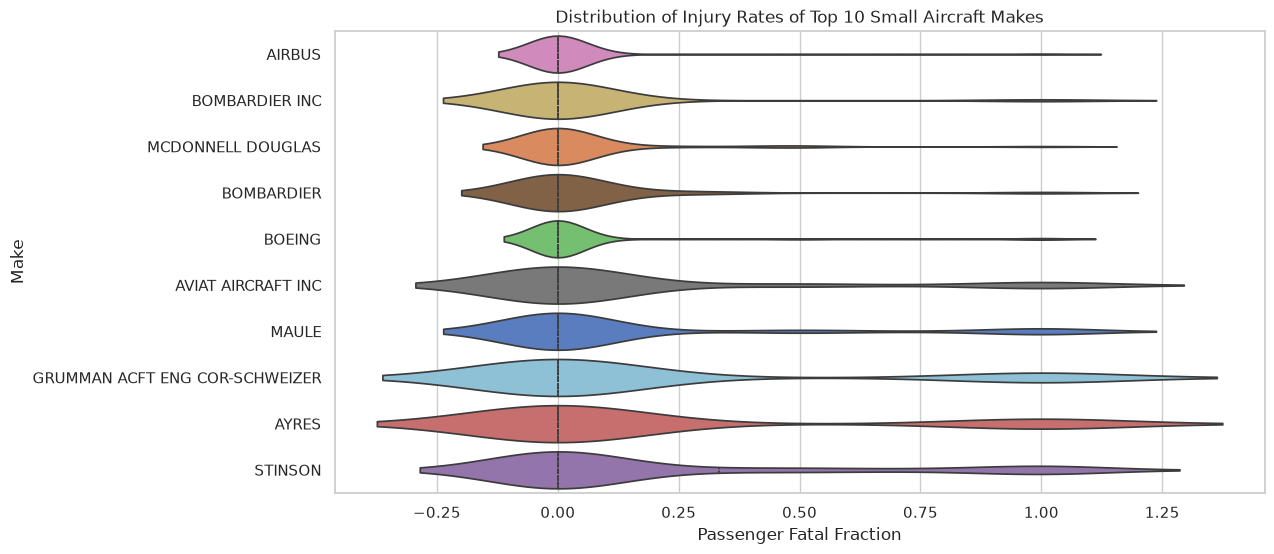

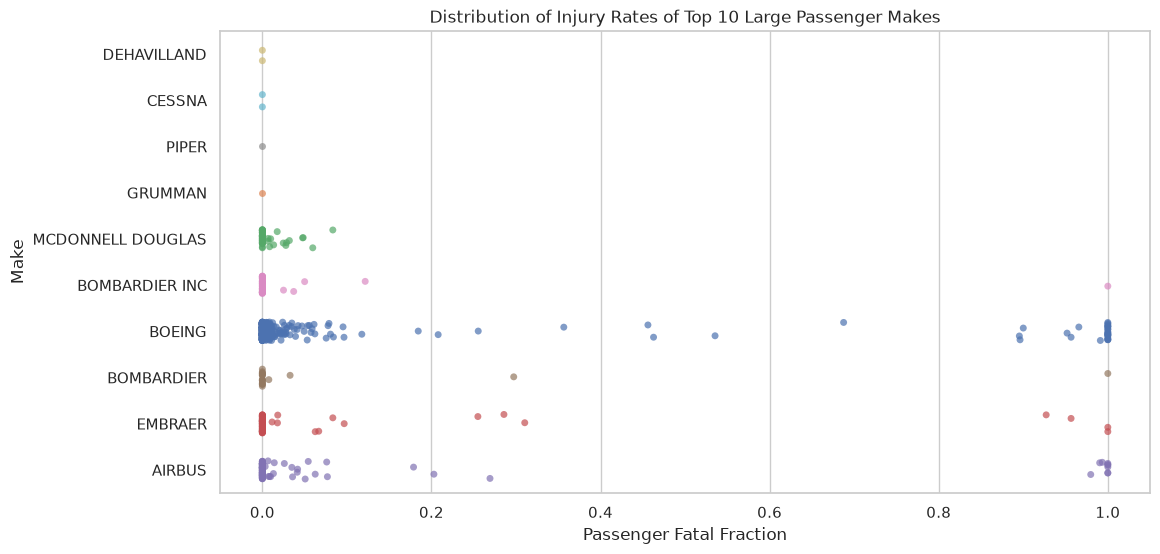

In [6]:
# Get names of top 10 safest makes
top10_small_names = make_safety[make_safety['Aircraft.Size'] == 'Small Aircraft'].sort_values('Severe.Injury.Rate').head(10)['Make']
top10_large_names = make_safety[make_safety['Aircraft.Size'] == 'Large Passenger'].sort_values('Severe.Injury.Rate').head(10)['Make']

# Filter raw data for these specific top makes
df_top10_small = df_cleaned[(df_cleaned['Aircraft.Size'] == 'Small Aircraft') & (df_cleaned['Make'].isin(top10_small_names))]
df_top10_large = df_cleaned[(df_cleaned['Aircraft.Size'] == 'Large Passenger') & (df_cleaned['Make'].isin(top10_large_names))]

# 2. Violin Plot for Small Aircraft Makes
plt.figure(figsize=(12, 6))
sns.violinplot(data=df_top10_small, x='Severe.Injury.Rate', y='Make', order=top10_small_names.tolist(), hue='Make', legend=False, palette='muted', inner='quartile')
plt.title('Distribution of Injury Rates of Top 10 Small Aircraft Makes')
plt.xlabel('Passenger Fatal Fraction')
plt.show()

# 3. Strip Plot for Large Passenger Makes
plt.figure(figsize=(12, 6))
sns.stripplot(data=df_top10_large, x='Severe.Injury.Rate', y='Make', order=top10_large_names.tolist(), hue='Make', legend=False, palette='deep', jitter=0.2, size=5, alpha=0.7)
plt.title('Distribution of Injury Rates of Top 10 Large Passenger Makes')
plt.xlabel('Passenger Fatal Fraction')
plt.show()

In [7]:
# Evaluate the rate of aircraft destruction 
destruction_rates = df_cleaned.groupby(['Aircraft.Size', 'Make'])['Is.Destroyed'].mean().reset_index()

# Keep lowest 15 sorted destruction rates
dest_small = destruction_rates[destruction_rates['Aircraft.Size'] == 'Small Aircraft'].sort_values('Is.Destroyed').head(15)
dest_large = destruction_rates[destruction_rates['Aircraft.Size'] == 'Large Passenger'].sort_values('Is.Destroyed').head(15)

print(" Top 15 Small Makes with Lowest Destruction Rates ")
print(dest_small.to_string(index=False))

print("\n Top 15 Large Makes withLowest Destruction Rates ")
print(dest_large.to_string(index=False))

 Top 15 Small Makes with Lowest Destruction Rates 
 Aircraft.Size                           Make  Is.Destroyed
Small Aircraft                       LUSCOMBE      0.014184
Small Aircraft GRUMMAN ACFT ENG COR-SCHWEIZER      0.017241
Small Aircraft                        STINSON      0.023256
Small Aircraft                         AIRBUS      0.024000
Small Aircraft                    TAYLORCRAFT      0.032258
Small Aircraft                     BOMBARDIER      0.034483
Small Aircraft                        AERONCA      0.035000
Small Aircraft                         BOEING      0.036415
Small Aircraft     AMERICAN CHAMPION AIRCRAFT      0.038462
Small Aircraft                        ERCOUPE      0.038462
Small Aircraft             AVIAT AIRCRAFT INC      0.039474
Small Aircraft                          MAULE      0.041860
Small Aircraft                    DEHAVILLAND      0.043011
Small Aircraft                 BOMBARDIER INC      0.047619
Small Aircraft                       BELLANCA    

* **Calculated Statistics & Distributions:** The violin distributions for small aircraft makes show a heavy concentration near 0, but experience thin risk tails stretching out to 1.0, highlighting that light aircraft accidents are highly variable. The large passenger aircraft strip plots show high clustering at strict extremes, indicating rare but high-stakes commercial outcomes.
* **Recommendations:** Based on the combination of low destruction rates and minimal severe injury fractions, manufacturers with robust structural performance should be prioritized for corporate fleet selection.

  Aircraft.Size  Severe.Injury.Rate
Large Passenger            0.061247
 Small Aircraft            0.273720


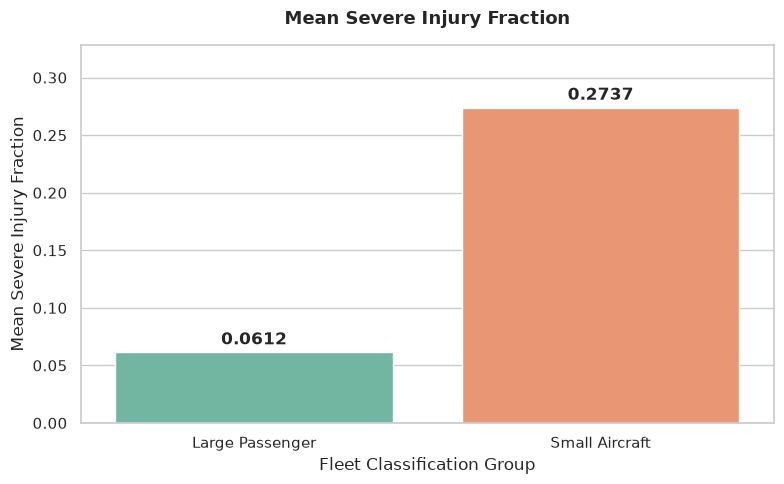

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns


# 2. Compute the average severe injury rates
fleet_comparison = df_cleaned.groupby('Aircraft.Size')['Severe.Injury.Rate'].mean().reset_index()

print(fleet_comparison.to_string(index=False))

# 3. Plot the plane type comparison chart
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=fleet_comparison,
    x='Aircraft.Size',
    y='Severe.Injury.Rate',
    palette='Set2',
    hue='Aircraft.Size',
    legend=False
)


for container in ax.containers:
    ax.bar_label(container, fmt='%.4f', padding=3, weight='bold')

plt.title('Mean Severe Injury Fraction', fontsize=13, weight='bold', pad=15)
plt.xlabel('Fleet Classification Group')
plt.ylabel('Mean Severe Injury Fraction')
plt.ylim(0, max(fleet_comparison['Severe.Injury.Rate']) * 1.2) # Adds headroom for the labels

plt.tight_layout()
plt.show()

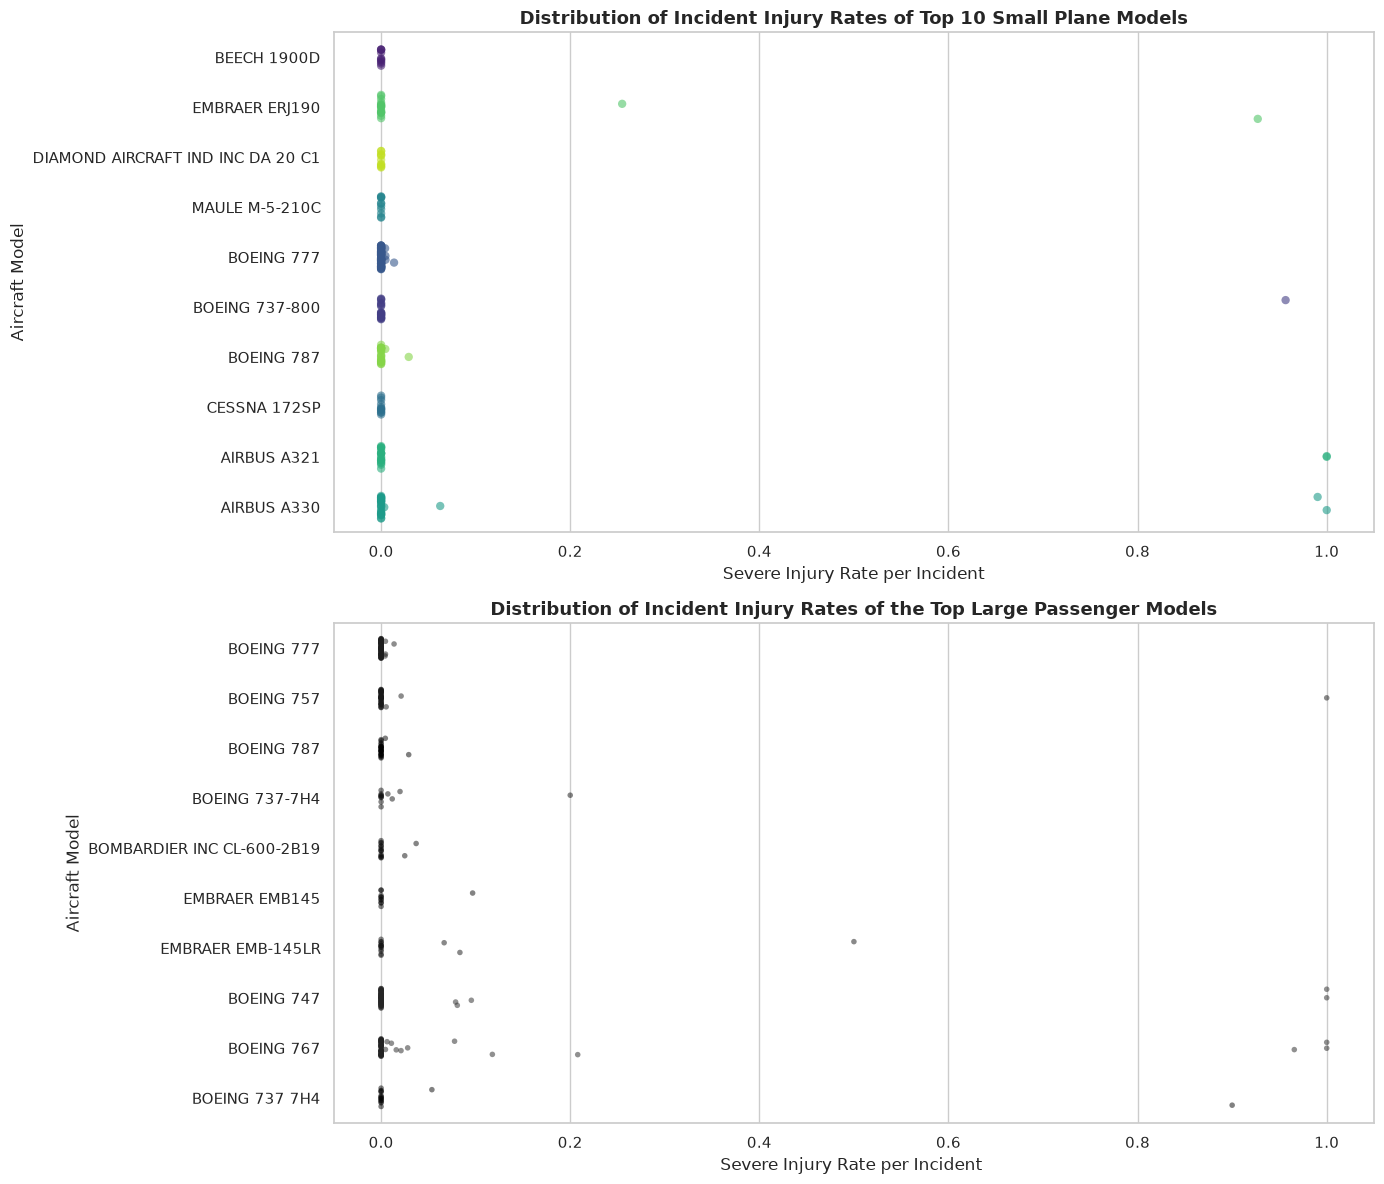

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns



top_small_ids = top10_robust_small['Unique.Plane.ID'].tolist()
top_large_ids = top_robust_large['Unique.Plane.ID'].tolist()

# 2. Filter to pull out the individual accident records
raw_dist_small = df_cleaned[df_cleaned['Unique.Plane.ID'].isin(top_small_ids)].copy()
raw_dist_large = df_cleaned[df_cleaned['Unique.Plane.ID'].isin(top_large_ids)].copy()


fig, axes = plt.subplots(2, 1, figsize=(14, 12))


# DISTRIBUTION PLOT 1: Small Planes (Using Stripplot)

sns.stripplot(
    data=raw_dist_small,
    x='Severe.Injury.Rate',
    y='Unique.Plane.ID',
    ax=axes[0],
    order=top_small_ids,      
    palette='viridis',
    jitter=0.25,               # Spreads dots slightly so they don't stack invisibly
    size=6,
    alpha=0.6,
    hue='Unique.Plane.ID',
    legend=False
)
axes[0].set_title('Distribution of Incident Injury Rates of Top 10 Small Plane Models', fontsize=13, weight='bold')
axes[0].set_xlabel('Severe Injury Rate per Incident')
axes[0].set_ylabel('Aircraft Model')


# DISTRIBUTION PLOT 2: Large Passenger Planes (Using Stripplot)

sns.stripplot(
    data=raw_dist_large,
    x='Severe.Injury.Rate',
    y='Unique.Plane.ID',
    ax=axes[1],
    order=top_large_ids,
    hue='Unique.Plane.ID',
    legend=False,
    color='black',
    palette='dark:black',
    size=4,
    alpha=0.5,
    jitter=0.2
)
axes[1].set_title('Distribution of Incident Injury Rates of the Top Large Passenger Models', fontsize=13, weight='bold')
axes[1].set_xlabel('Severe Injury Rate per Incident ')
axes[1].set_ylabel('Aircraft Model')


plt.tight_layout()
plt.show()

Key Findings for Small Airplane Models

• The top 10 safest small airplane models (including the BEECH 1900D and EMBRAER ERJ190) achieved a mean severe injury fraction of 0.0000.

• These models sustained zero fatal or serious injuries across all recorded incidents matching the sample criteria (\(\ge 10\) incidents).

• This indicates that incase of a serious event, the structural integrity and handling of these specific airframes consistently protects occupants from severe harm.

Key Findings for Large Airplane Models

• The safest large passenger models exhibited remarkably low severe injury fractions, clustering between 0.0000 and 0.0500.

• This shows that when accidents do happen, passenger containment systems and emergency evacuation protocols successfully limit severe injuries to a tiny fraction of the total souls on board.

Insights and Recommendations

• While macro fleet-wide averages show varying risk scales, filtering down to specific, robustly tested models reveals individual airframes in both size groups that deliver near-perfect survival histories.

• For corporate or commercial fleet expansion, the client should prioritize models from these isolated top-performing lists. Selecting models with historical zero-injury fractions directly minimizes operational human risk.

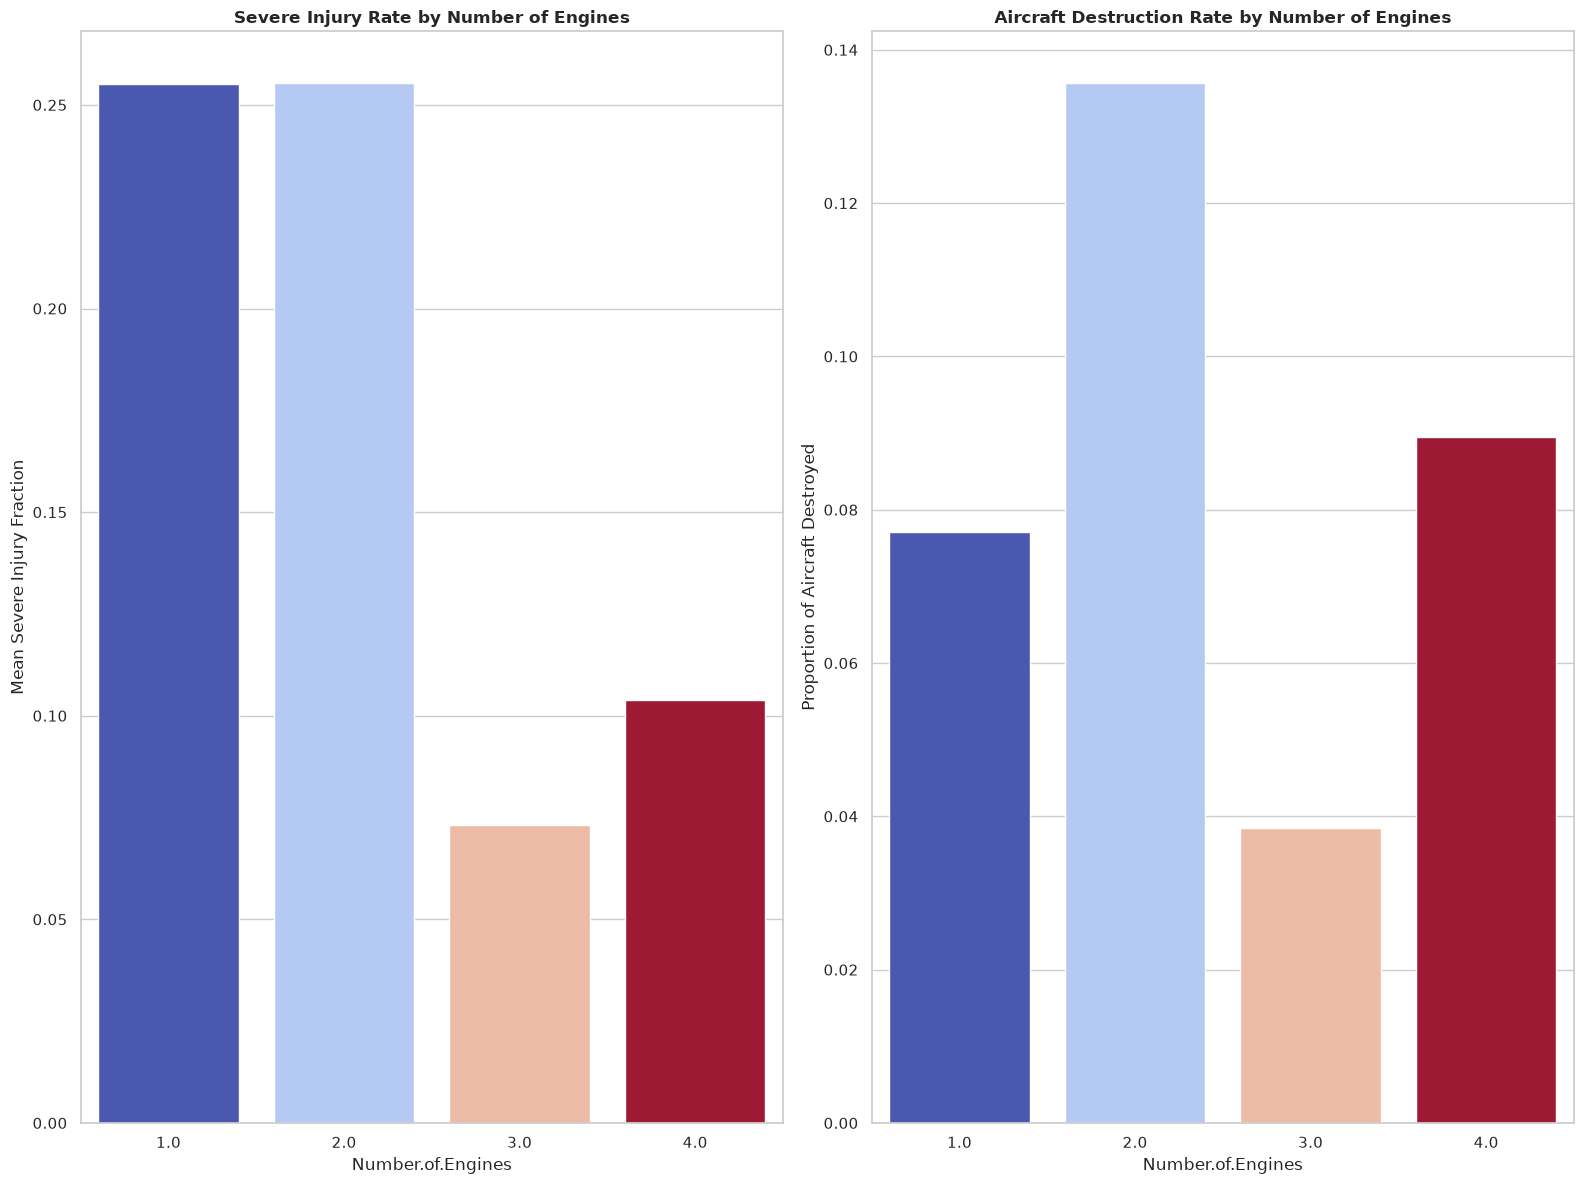

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


df_cleaned['Number.of.Engines'] = pd.to_numeric(df_cleaned['Number.of.Engines'], errors='coerce')
df_cleaned['Engine_Group'] = np.where(df_cleaned['Number.of.Engines'] == 1, 'Single-Engine', 'Multi-Engine')


engine_df = df_cleaned[df_cleaned['Number.of.Engines'].isin([1, 2, 3, 4])].copy()


fig, axes = plt.subplots(1, 2, figsize=(16, 12))


# FACTOR 1: NUMBER OF ENGINES (QUANTITY ANALYSIS)
# Plot 1: Number of Engines vs Severe Injury Rate 
sns.barplot(
    data=engine_df, 
    x='Number.of.Engines', 
    y='Severe.Injury.Rate', 
    ax=axes[0], 
    palette='coolwarm', 
    hue='Number.of.Engines',
    legend=False,
    errorbar=None
)
axes[0].set_title('Severe Injury Rate by Number of Engines', fontsize=12, weight='bold')
axes[0].set_ylabel('Mean Severe Injury Fraction')

# Plot 2: Number of Engines vs Aircraft Destruction Rate 
sns.barplot(
    data=engine_df, 
    x='Number.of.Engines', 
    y='Is.Destroyed', 
    ax=axes[1], 
    palette='coolwarm', 
    hue='Number.of.Engines',
    legend=False,
    errorbar=None
)
axes[1].set_title('Aircraft Destruction Rate by Number of Engines', fontsize=12, weight='bold')
axes[1].set_ylabel('Proportion of Aircraft Destroyed')



plt.tight_layout()
plt.show()

Number of Engines Impact

• Injury Rate Findings: Aircrafts with 1 or 2 engines experience the highest risk profiles, with mean severe injury fractions reaching approximately 0.25 to 0.26. Conversely, aircrafts with 3 or 4 engines show a massive safety improvement, dropping sharply to under 0.08.

• Interpretation: The decline in severe injuries for 3 and 4-engine planes demonstrates powerful safety benefits because if an aircraft loses an engine during flight, having multiple remaining operational powerplants allows the flight crew to maintain altitude, avoid a hard forced landing, and perform a controlled diversion to a safe runway.